# Capítulo 5 · Actividad: ¿cuánto consume este auto?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/02_actividad_mpg_regresion.ipynb)

Entrena una **regresión** que prediga el rendimiento de un auto en **millas por galón** (`mpg`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

| Variable | Significado |
|---|---|
| `mpg` | **Target**: millas por galón (más alto = consume menos) |
| `cylinders` | Número de cilindros |
| `displacement` | Cilindrada del motor (pulgadas cúbicas) |
| `horsepower` | Potencia (caballos de fuerza) |
| `weight` | Peso (libras) |
| `acceleration` | Segundos para ir de 0 a 60 mph |
| `model_year` | Año del modelo (70 = 1970) |
| `origin` | Región de origen: `usa`, `europe` o `japan` |
| `name` | Nombre del auto |

Como mínimo, tu notebook debe incluir:

- Un **modelo lineal base**: coeficientes, métricas de error y $R^2$.
- Los mismos modelos que vimos en clase: regresión simple, lineal múltiple, Ridge, Lasso, polinomial y RANSAC.
- Una **tabla final** comparando los modelos con validación cruzada y test, y tus **conclusiones**: ¿qué modelo elegirías y por qué?

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.linear_model import Lasso, LinearRegression, RANSACRegressor, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)
#
# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

autos = pd.read_csv(DATA_DIR / "mpg.csv")
autos.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [2]:
# Exploración Inicial

autos.shape

(398, 9)

In [3]:
autos.info()


<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [4]:
autos.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [5]:
pd.DataFrame({
    "nulos": autos.isna().sum(),
    "porcentaje": autos.isna().mean() * 100
}).sort_values("nulos", ascending=False)



,nulos,porcentaje
horsepower,6,1.507538
mpg,0,0.000000
cylinders,0,0.000000
displacement,0,0.000000
weight,0,0.000000
acceleration,0,0.000000
model_year,0,0.000000
origin,0,0.000000
name,0,0.000000


In [6]:
#Detección de duplicados

autos.duplicated().sum()

np.int64(0)

In [7]:
## VARIABLE OBJETIVO ES EL MPG
autos["mpg"].value_counts(normalize=True)

mpg
13.0    0.050251
14.0    0.047739
18.0    0.042714
15.0    0.040201
26.0    0.035176
          ...   
28.1    0.002513
30.7    0.002513
24.2    0.002513
22.4    0.002513
44.0    0.002513
Name: proportion, Length: 129, dtype: float64

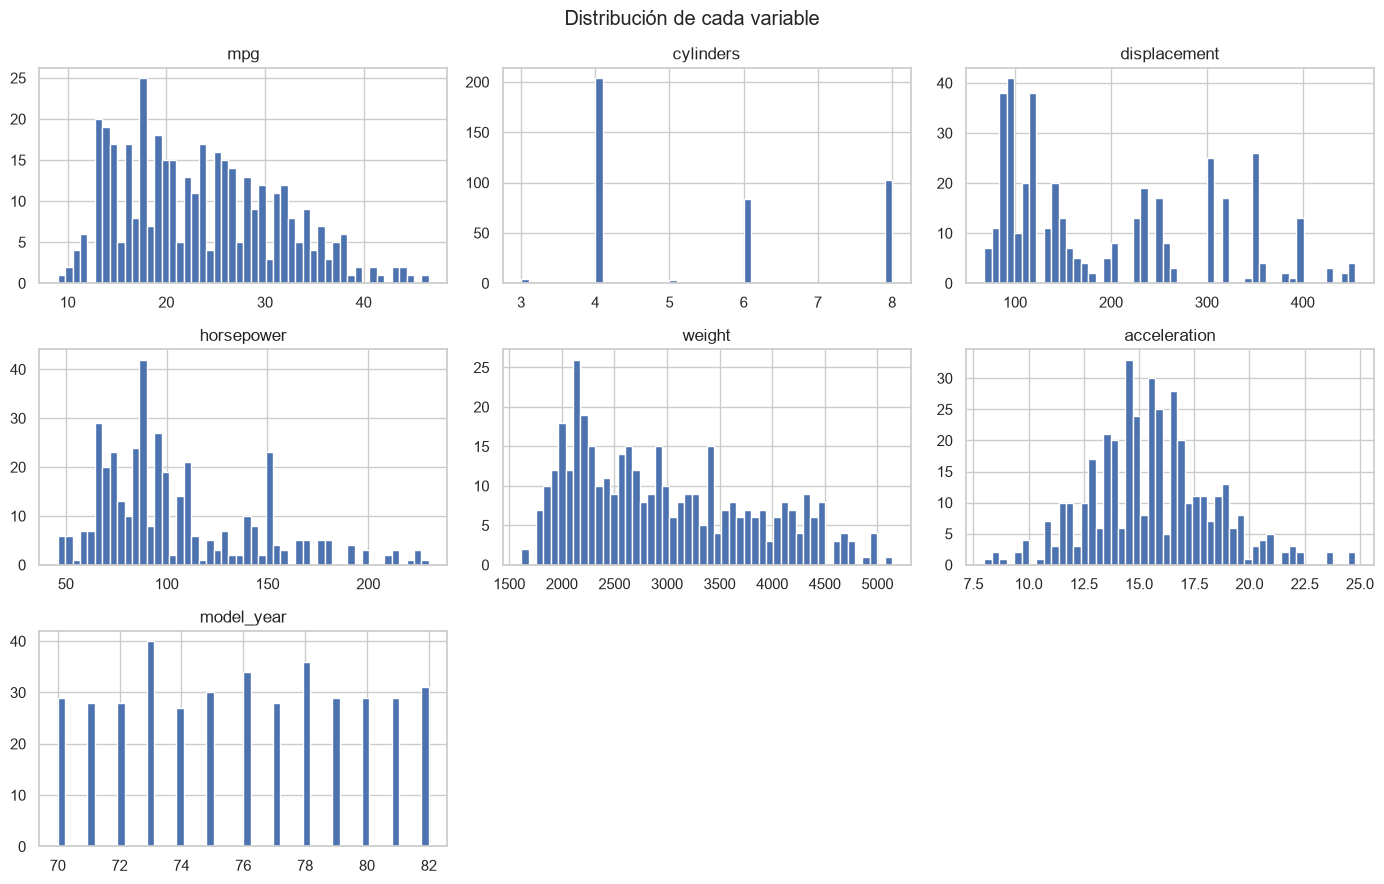

In [8]:
autos.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

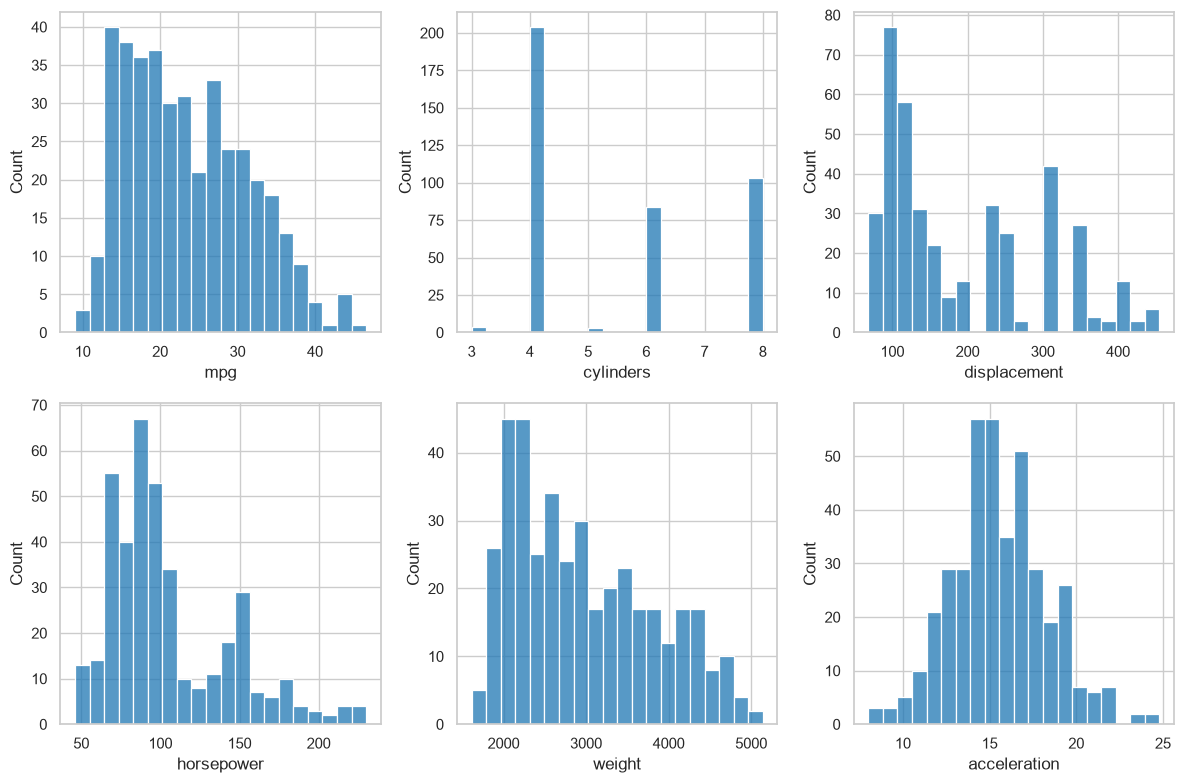

In [9]:
autos_numeric = autos.select_dtypes(include="number")
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for column, ax in zip(autos_numeric.columns, axes.flat):
    sns.histplot(data=autos_numeric, x=column, bins=20, color="tab:blue", ax=ax)
plt.tight_layout()
plt.show()





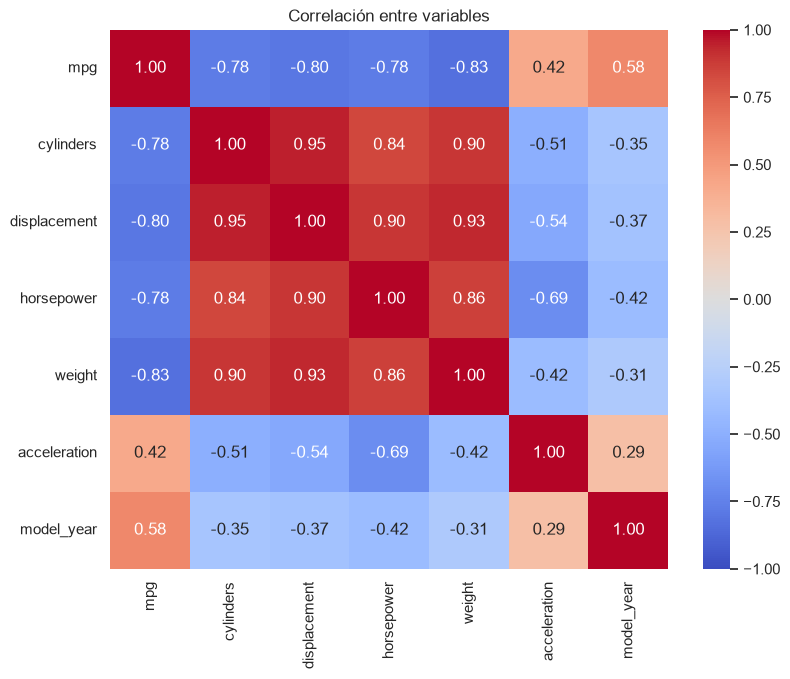

In [10]:
correlaciones = autos.select_dtypes(include="number").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

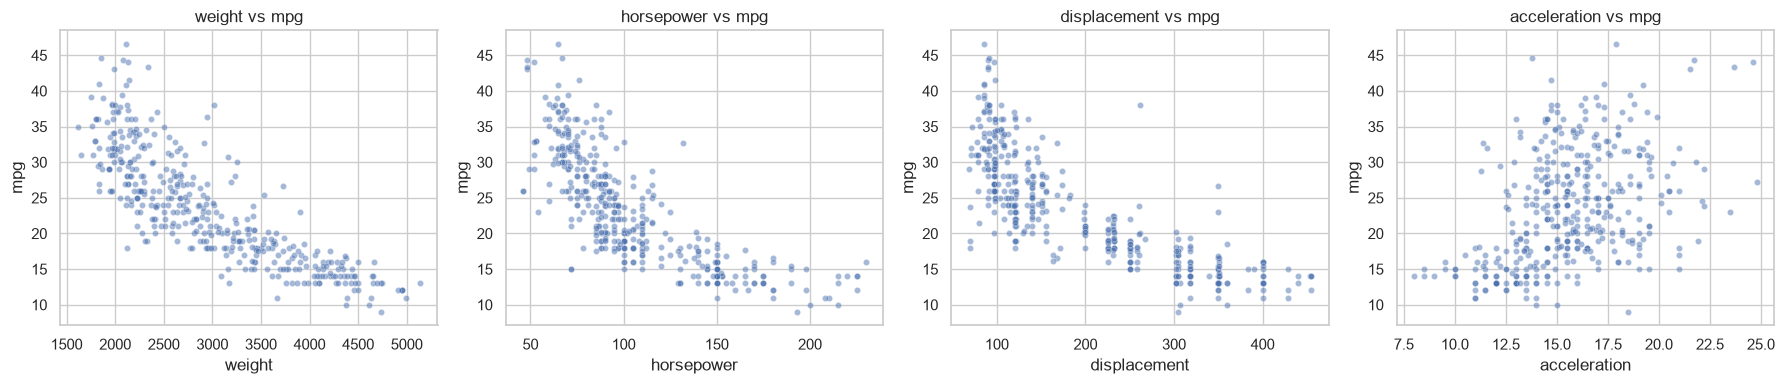

In [11]:
variables = ["weight", "horsepower", "displacement", "acceleration"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for variable, ax in zip(variables, axes):
    sns.scatterplot(data=autos, x=variable, y="mpg", alpha=0.5, s=20, ax=ax)
    ax.set_title(f"{variable} vs mpg")
plt.tight_layout()
plt.show()

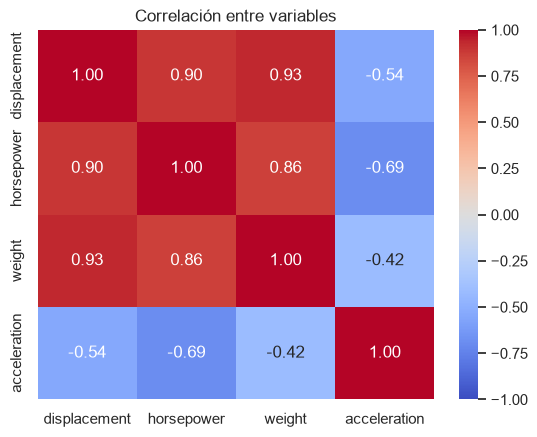

In [12]:
numericas = autos.assign(sex=autos["mpg"].astype(float))[["displacement", "horsepower", "weight", "acceleration"]]

sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()


## Dentro de lo hablado, consideramos tenerlo por la naturaleza de la variable. [Weight]
# [mpg]


In [13]:
numericas = autos.assign(sex=autos["mpg"].astype(float))[["displacement", "horsepower", "acceleration","weight"]]

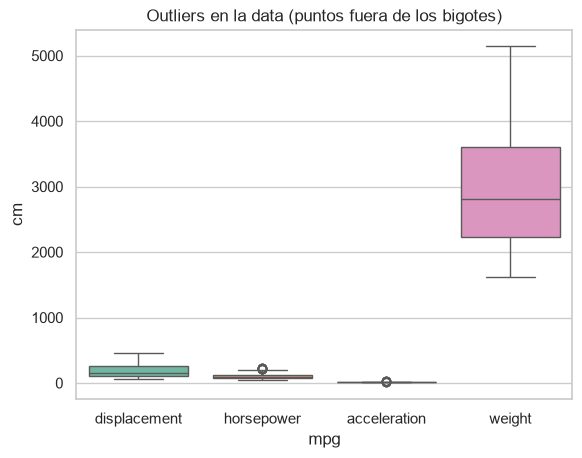

In [14]:
ax = sns.boxplot(data=numericas.melt(var_name="mpg", value_name="cm"),
                 x="mpg", y="cm", hue="mpg", palette="Set2")
ax.set_title("Outliers en la data (puntos fuera de los bigotes)")
plt.show()

In [15]:
##RELLENAR VALORES VACÍOS
# 2) Calcula el precio unitario promedio de cada región. Utiliza el método groupby().
datos_vacios = autos["horsepower"].fillna(autos.groupby(["cylinders","model_year"])["horsepower"].transform("mean"))
print(datos_vacios)

0      130.0
1      165.0
2      150.0
3      150.0
4      140.0
       ...  
393     86.0
394     52.0
395     84.0
396     79.0
397     82.0
Name: horsepower, Length: 398, dtype: float64


Valor máximo de mpg: 46.6
Distritos con ese valor:      1


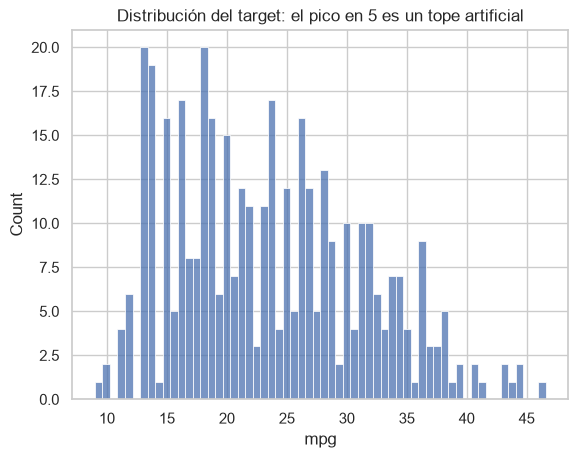

In [16]:
print("Valor máximo de mpg:", autos["mpg"].max())
print("Distritos con ese valor:     ", (autos["mpg"] == autos["mpg"].max()).sum())

ax = sns.histplot(data=autos, x="mpg", bins=60)
ax.set_title("Distribución del target: el pico en 5 es un tope artificial")
plt.show()

In [17]:
X = autos.drop(columns="mpg")
y = autos["mpg"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)})

Train: (318, 8) | Test: (80, 8)


,train,test
mpg,,
9.0,0.003145,NaN
10.0,0.003145,0.0125
11.0,0.009434,0.0125
12.0,0.012579,0.0250
13.0,0.050314,0.0500
...,...,...
43.4,0.003145,NaN
44.0,NaN,0.0125
44.3,0.003145,NaN
